## Time Series Grid SANOS Market Generation Test

This notebook computes historic time series for implied vols, fitting error, DLV vs a gixed NMS grid.



In [1]:

import os
os.environ["JAX_ENABLE_X64"] = "True"

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.sanos.sanos_tools
%aimport quantdata.sanos.arbfree
%aimport quantdata.sanos.sanos
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.interpolated


In [2]:

from cdxcore.pretty import PrettyObject
from quantdata.dysanos.grid.interpolated import GridConfig, interpolate_grid, interpolate_time_series, Context
from quantdata.biz_calendar import DateRange
from quantdata.pool import PoolConfig
from datetime import date

def load(mode : str, verbose : Context = Context.all ) -> PrettyObject:
    r = PrettyObject()
    r.pool_config = PoolConfig(num_workers=8, threading=False)
    r.grid_config = GridConfig(smoothness=0.25, mode=mode)
    r.ts = PrettyObject( interpolate_time_series( "SPX", DateRange(start=date(2025, 1, 1), end=date(2025, 8, 30)), grid_config=r.grid_config, pool_config=r.pool_config, verbose=verbose ) )
    return r

r_nms = load("nms")
print(f"nms /done - found {len(r_nms.ts['dates'])} dates.")

#r_logK = load("logK")
#print(f"logK /done - found {len(r_logK.ts['dates'])} dates.")



nms /done - found 163 dates.


00: Preparing data set for 0.25-smooth@10 midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=200,a=ReLU,b=True) traing TrainConfig(num_epochs=5000, lr=0.001, weight_decay=0.0001) on Env(prec=32,device=cuda,debug=False)... done; initial loss is 0.06723. This took 0.37s.


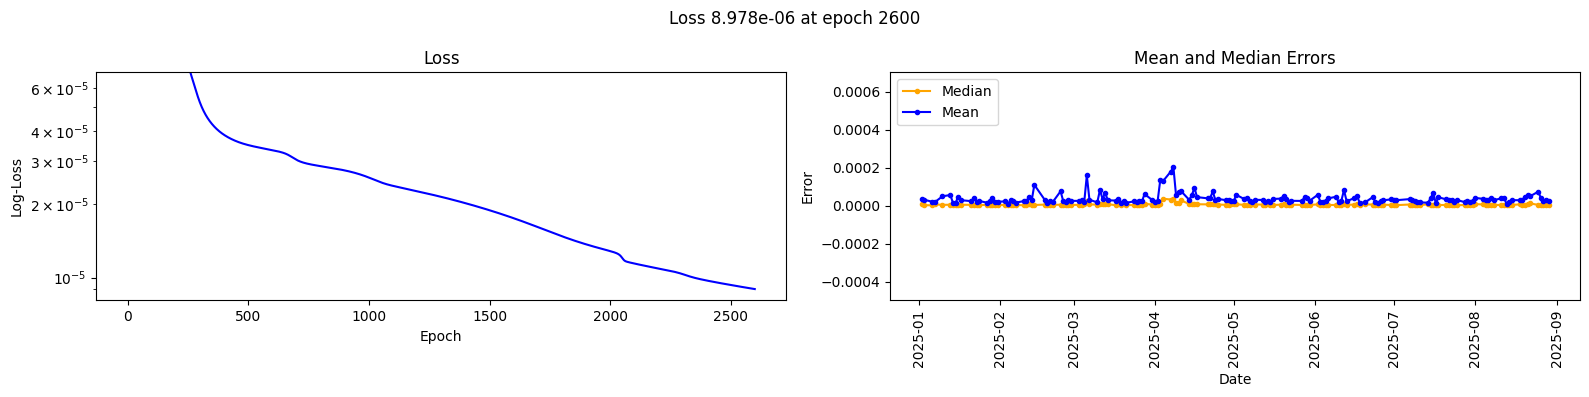

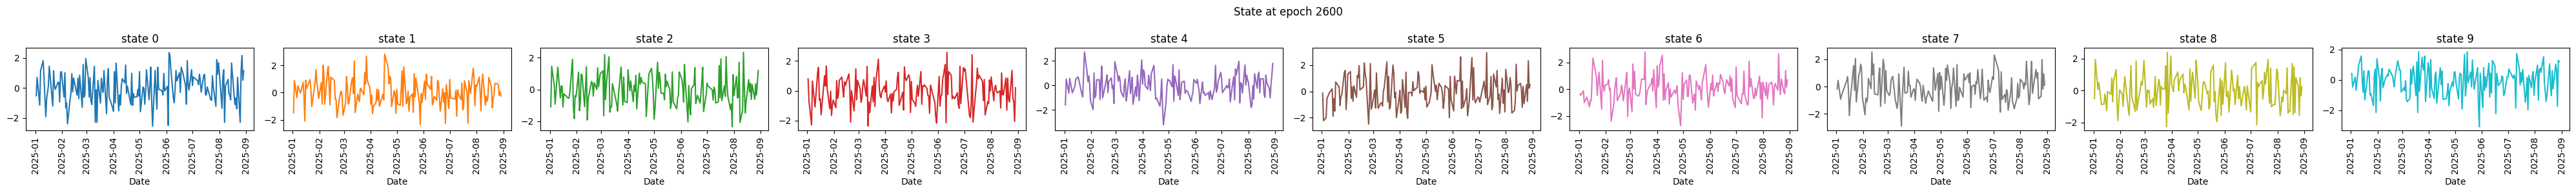

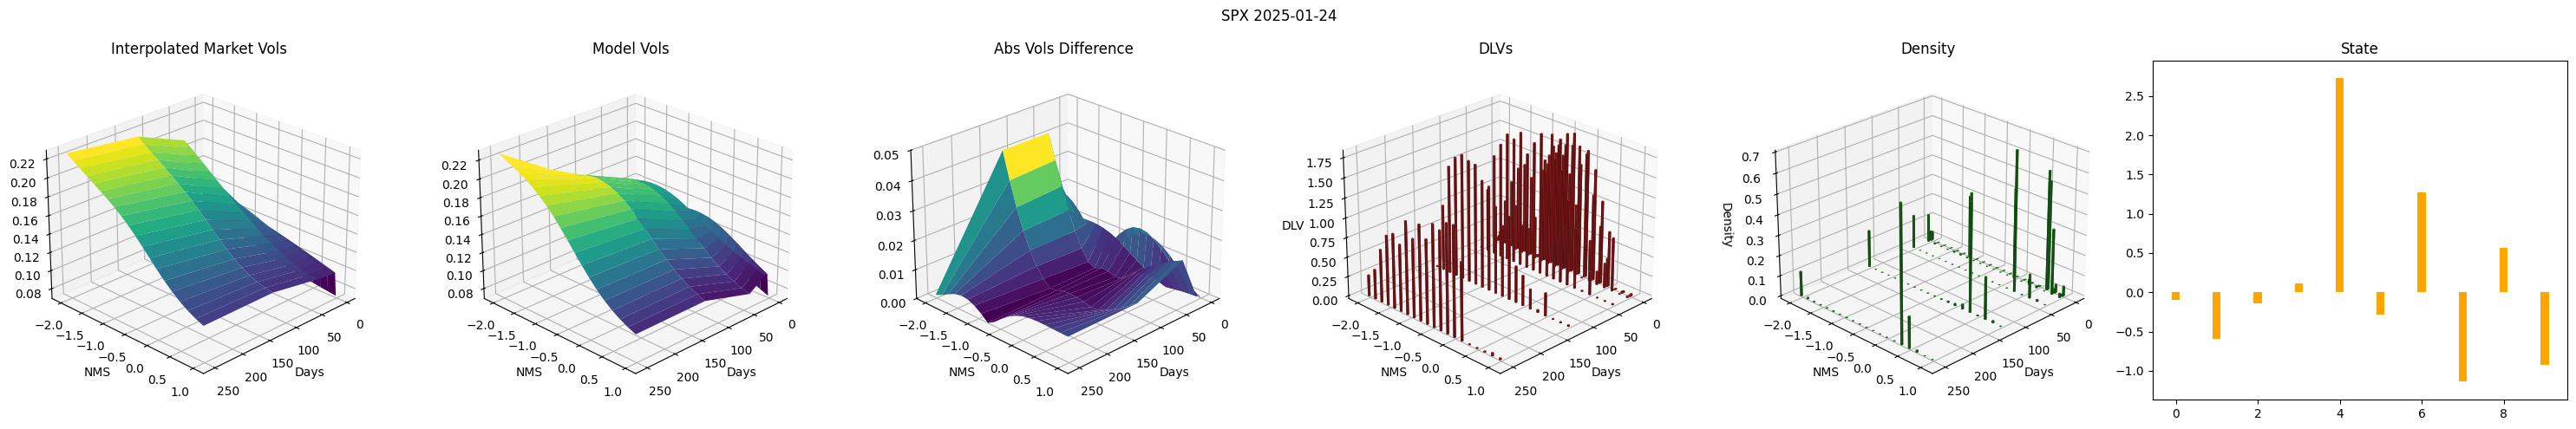

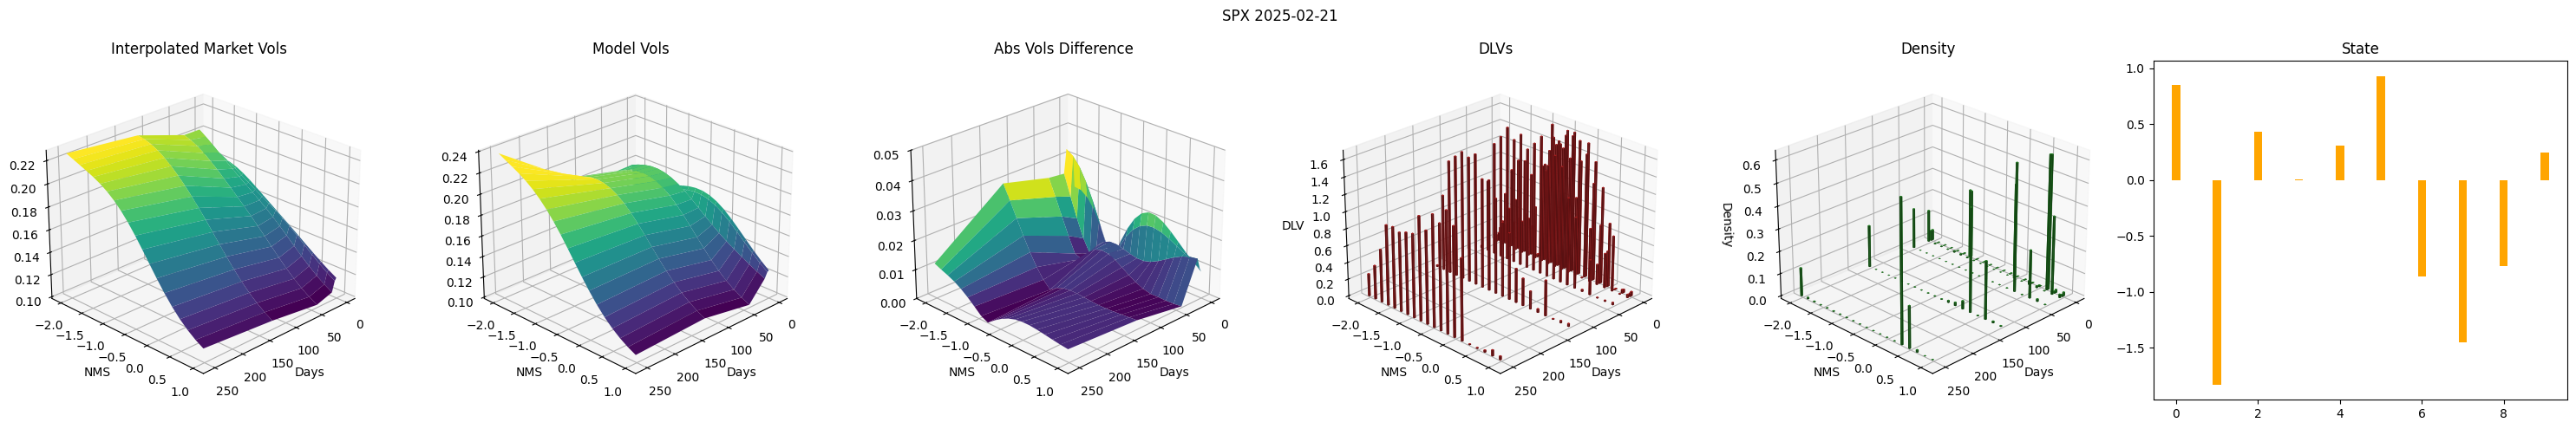

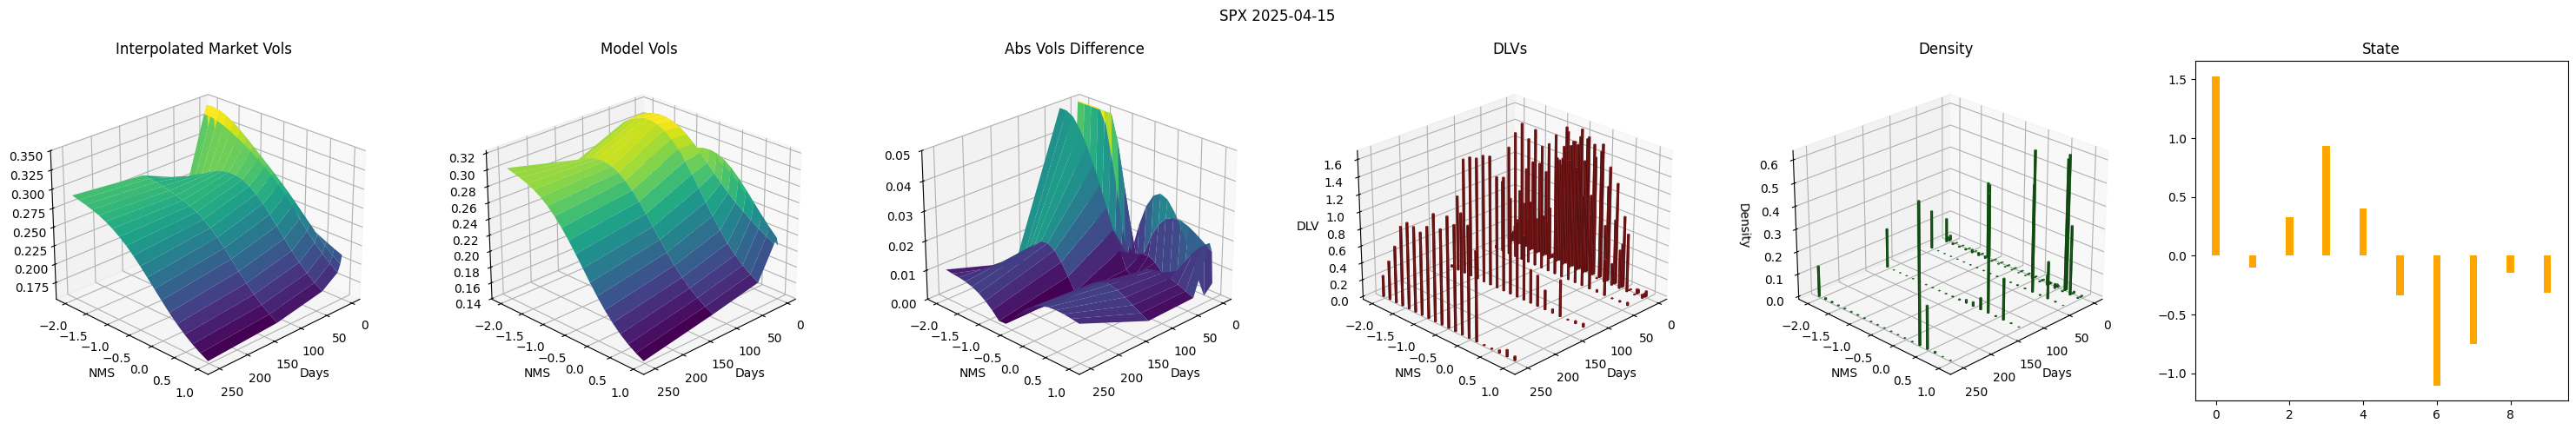

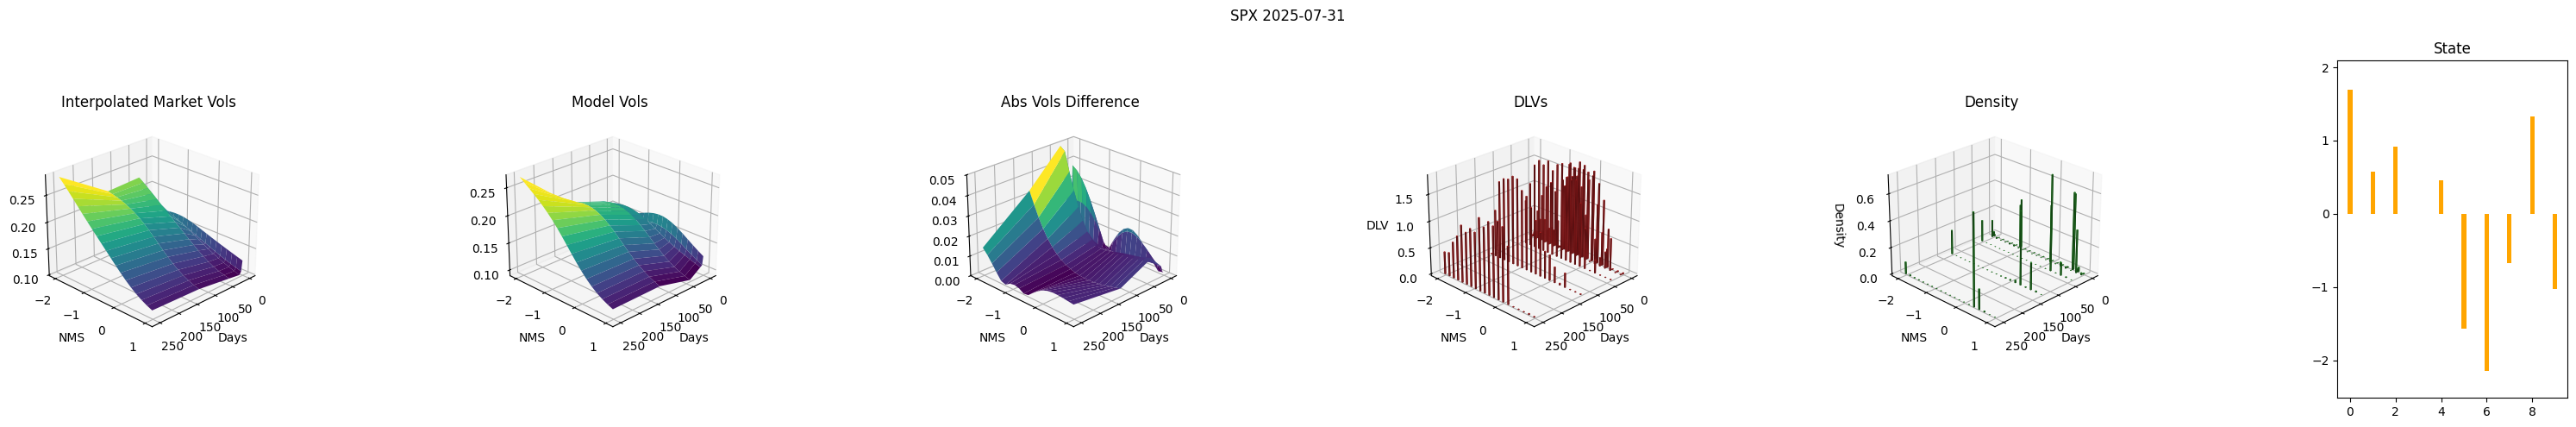

00: Training 0.25-smooth@10 midlv=0.01,mxdlv=2.00,vsq=0.0001 st=FF(d=2,w=200,a=ReLU,b=True) with TrainConfig(num_epochs=5000, lr=0.001, weight_decay=0.0001) on Env(prec=32,device=cuda,debug=False):
01:   Epoch 1/5000, Loss: 0.06723. So far this took 0.38s.

/home/hans/vqdata/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


01:   Epoch 2600/5000, Loss: 8.982e-06. So far this took 1:42.

In [ ]:
from cdxcore.bs import bs
from flax.nnx import state

from quantdata.biz_calendar import DAYS_PER_YEAR
from quantdata.dysanos.grid.torch_model import BaseEnvironment, SanosCompressorConfig, SanosCompressor, FeedForward, torch
from dataclasses import dataclass
import numpy as np
from cdxcore.dynaplot import FigStore, colors_tableau, figure, m_o_m


class Display(object):

    class ExpiryGfx(object):

        def __init__(self, ticker, *, date, index, ts, mdl_config, trn_config, isNMS ):
            self.fig       = figure(f"{ticker} {date}", col_size=5, row_size=5, columns=None )
            self.index     = index
            self.date      = date
            self.ts        = ts
            self.mdl_config = mdl_config
            self.trn_config = trn_config
            self.store      = FigStore()
            self.isNMS      = isNMS

            self.expiries = ts['expiries'][self.index,:]
            self.xstrikes = ts['xstrikes'][self.index,:,:]
            self.nms      = ts['nms'][self.index,:,:]
            self.mids     = ts['mids'][self.index,:,:]
            self.mid_vols = ts['mid_vols'][self.index,:,:]

            fit_vols      = ts['mid_vols'][self.index,:,:]
            fit_dlvsqs    = ts['fit_dlvsqs'][self.index,:,:]

            strikes       = self.nms if self.isNMS else self.xstrikes[:,1:-1]
            strk_name     = "NMS" if self.isNMS else "K"
    
            self.expiries_block = np.stack( [ self.expiries*DAYS_PER_YEAR ]*(self.xstrikes.shape[-1]-2), axis=-1 )

            assert self.expiries_block.shape == self.nms.shape == self.mid_vols.shape, f"Expected expiries_block, nms and mid_vols to have the same shape, but found {self.expiries_block.shape}, {self.nms.shape} and {self.mid_vols.shape}"
            self.axMarketVols = self.fig.add_subplot("Interpolated Market Vols", projection="3d") 
            self.axMarketVols.plot_surface( self.expiries_block, strikes, self.mid_vols, cmap='viridis', edgecolor='none')
            self.axMarketVols.set_xlabel("Days")
            self.axMarketVols.set_ylabel(strk_name)
            self.axMarketVols.view_init(elev=25, azim=45) 

            assert self.expiries_block.shape == self.nms.shape == fit_vols.shape, f"Expected expiries_block, nms and fit_vols to have the same shape, but found {self.expiries_block.shape}, {self.nms.shape} and {fit_vols.shape}"
            self.axFittedVols = self.fig.add_subplot("Model Vols", projection="3d")
            self.store += self.axFittedVols.plot_surface(self.expiries_block, strikes, fit_vols, cmap='viridis', edgecolor='none')
            self.axFittedVols.set_xlabel("Days")
            self.axFittedVols.set_ylabel(strk_name)
            self.axFittedVols.view_init(elev=25, azim=45) 

            assert self.expiries_block.shape == self.nms.shape == np.abs(fit_vols - self.mid_vols).shape, f"Expected expiries_block, nms and fit_vols to have the same shape, but found {self.expiries_block.shape}, {self.nms.shape} and {np.abs(fit_vols - self.mid_vols).shape}"
            self.axAbsVolsDiff = self.fig.add_subplot("Abs Vols Difference", projection="3d")
            self.store += self.axAbsVolsDiff.plot_surface(self.expiries_block, strikes, np.abs(fit_vols - self.mid_vols), cmap='viridis', edgecolor='none')
            self.axAbsVolsDiff.set_xlabel("Days")
            self.axAbsVolsDiff.set_ylabel(strk_name)
            self.axAbsVolsDiff.set_zlim( 0., 0.05 )
            self.axAbsVolsDiff.view_init(elev=25, azim=45) 

            x = np.reshape(self.expiries_block, (-1,))
            y = np.reshape(strikes, (-1,))
            dx = (x.max() - x.min())/100.
            dy = (y.max() - y.min())/100.

            z = np.reshape(np.sqrt(fit_dlvsqs),(-1,))
            assert x.shape == y.shape == z.shape, f"Expected x, y and z to have the same shape, but found {x.shape}, {y.shape} and {z.shape}"
            self.axDLVs = self.fig.add_subplot("DLVs", projection="3d")
            self.store += self.axDLVs.bar3d(x=x, y=y, z=0.*z, dx=dx, dy=dy, dz=z, cmap="viridis", edgecolor='none' )
            self.axDLVs.set_xlabel("Days")
            self.axDLVs.set_ylabel(strk_name)
            self.axDLVs.set_zlabel("DLV")
            self.axDLVs.view_init(elev=25, azim=45) 

            self.axDensity = self.fig.add_subplot("Density", projection="3d")
            #z = np.reshape(np.sqrt(fit_dlvsqs),(-1,))
            #self.store += self.axDensity.bar3d(x=x, y=y, z=0.*z, dx=dx, dy=dy, dz=z, cmap="viridis", edgecolor='none' )
            self.axDensity.set_xlabel("Days")
            self.axDensity.set_ylabel(strk_name)
            self.axDensity.set_zlabel("Density")
            self.axDensity.view_init(elev=25, azim=45)

            # state
            self.axState = self.fig.add_subplot("State")            
            self.store += self.axState.bar( np.arange(mdl_config.num_state),np.zeros((mdl_config.num_state,)), width=0.2 )

            self.fig.render()

        def update(self, *, calls, dlvsqs, xdensities, state ):

            strikes       = self.nms if self.isNMS else self.xstrikes[:,1:-1]
            strk_name     = "NMS" if self.isNMS else "K"
            x = np.reshape(self.expiries_block, (-1,))
            y = np.reshape(strikes, (-1,))
            dx = (x.max() - x.min())/100.
            dy = (y.max() - y.min())/100.

            vols = bs.implied( k=self.xstrikes[:,1:-1], prices=calls, sqrtT=np.sqrt(self.expiries[:,None]) )

            self.store.clear()
            self.store += self.axFittedVols.plot_surface(self.expiries_block, strikes, vols, cmap='viridis', edgecolor='none')
            self.store += self.axAbsVolsDiff.plot_surface(self.expiries_block, strikes, np.clip( np.abs(vols - self.mid_vols), 0., 0.05), cmap='viridis', edgecolor='none')

            z = np.reshape(np.sqrt(dlvsqs),(-1,))
            self.store += self.axDLVs.bar3d(x=x, y=y, z=0.*z, dx=dx, dy=dy, dz=z, cmap="viridis", edgecolor='none' )

            z = np.reshape(xdensities[:,1:-1],(-1,))
            self.store += self.axDensity.bar3d(x=x, y=y, z=0.*z, dx=dx, dy=dy, dz=z, cmap="viridis", edgecolor='none' )

            self.store += self.axState.bar( np.arange(mdl_config.num_state),state, width=0.2, color="orange" )
            self.fig.render()

    def __init__(self, ticker, *, data, num_viz_dates, isNMS, mdl_config, trn_config, state0 ):
        self.data          = data
        self.num_viz_dates = num_viz_dates
        self.isNMS         = isNMS
        self.mdl_config    = mdl_config
        self.trn_config    = trn_config
        self.store         = FigStore()

        self._figs = {}

        # learning
        self.fig_lrn = figure(f"Learning rate {ticker}", col_size=8, row_size=4, columns=None) 
        self.ax_lrn  = self.fig_lrn.add_subplot("Loss")
        self.ax_lrn.set_xlabel("Epoch")
        self.ax_lrn.set_ylabel("Log-Loss")
        self.ax_lrn.set_yscale("log")

        self.ax_error = self.fig_lrn.add_subplot("Mean and Median Errors")
        self.store += self.ax_error.plot(self.data.ts.dates, np.zeros((len(self.data.ts.dates),)), ".-", color="orange", label="Median")
        self.store += self.ax_error.plot(self.data.ts.dates, np.zeros((len(self.data.ts.dates),)), ".-", color="blue", label="Mean")
        self.ax_error.set_xlabel("Date")
        self.ax_error.set_ylabel("Error")
        self.ax_error.tick_params(axis="x", labelrotation=90)
        self.ax_error.legend(loc="upper left")

        self.fig_lrn.render()

        # state
        dates            = data.ts.dates
        self.ax_states = []
        self.fig_state = figure(f"State", col_size=4, row_size=3, columns=mdl_config.num_state )
        colors         = colors_tableau()
        self.ax_states = []
        assert state0.shape[1] == mdl_config.num_state, f"Expected state to have shape[1] == {mdl_config.num_state}, but found {state0.shape[1]}"   
        for istate in range(mdl_config.num_state):
            ax = self.fig_state.add_subplot(f"state {istate}")
            self.ax_states.append(ax)
            self.store += ax.plot(self.data.ts.dates, state0[:,istate], color=next(colors))
            ax.set_xlabel("Date")
            ax.tick_params(axis="x", labelrotation=90)
        self.fig_state.render()

        self.indices     = sorted( np.random.choice( np.arange(len(dates)), size=min(self.num_viz_dates, len(dates)), replace=False ) )
        self.expiry_gfxs = { ix: self.ExpiryGfx(ticker=ticker, date =dates[ix], index=ix, ts=self.data.ts, mdl_config=mdl_config, trn_config=trn_config, isNMS=self.isNMS) for ix in self.indices }

    def __call__(self, losses, loss, *, calls, xdensities, dlvsqs, errors, weights, state ):

        self.store.clear()

        # losses
        epoch      =  len(losses)
        losses     =  np.asanyarray(losses)
        self.store += self.ax_lrn.plot(np.arange(len(losses)), losses, color="blue")
        self.ax_lrn.set_ylim( 0.9*min(losses), np.quantile(losses, 0.90 ) if len(losses) > 20 else 1.1*max(losses) )
        self.fig_lrn.suptitle(f"Loss {loss:.4g} at epoch {epoch}")

        medians = [ np.median(err[wgt>0]) for err, wgt in zip(errors, weights) ]
        means = [ np.mean(err[wgt>0]) for err, wgt in zip(errors, weights) ]
        medians = np.array(medians)
        means = np.array(means)
        assert medians.shape == means.shape == (len(self.data.ts.dates),), f"Expected medians and means to have shape {(len(self.data.ts.dates),)}, but found {medians.shape} and {means.shape}"
        self.store += self.ax_error.plot(self.data.ts.dates, medians, ".-", color="orange", label="Median")
        self.store += self.ax_error.plot(self.data.ts.dates, means, ".-", color="blue", label="Mean")
        self.ax_error.set_ylim(m_o_m(medians,means))
        self.fig_lrn.render()

        # states
        assert state.shape[1] == len(self.ax_states), f"Expected state to have shape[1] == {len(self.ax_states)}, but found {state.shape[1]}"   
        colors  = colors_tableau()
        for istate, axstate in enumerate(self.ax_states):
            self.store += axstate.plot(self.data.ts.dates, state[:,istate], color=next(colors))
        self.fig_state.suptitle(f"State at epoch {epoch}")
        self.fig_state.render()

        # rest
        for ix, gfx in self.expiry_gfxs.items():
            gfx.update( calls=calls[ix,:,:], xdensities=xdensities[ix,:,:], dlvsqs=dlvsqs[ix,:,:], state=state[ix,:] )



@dataclass(frozen=True)
class TrainConfig:
    num_epochs : int = 5000
    lr : float = 1E-3
    weight_decay : float = 1e-4

def train( data : PrettyObject,*,
           mdl_config : SanosCompressorConfig, 
           trn_config: TrainConfig = TrainConfig(),
           num_viz_dates : int = 4,
           isNMS : bool = True,
           verbose : Context = Context.all ) -> dict:
    """
    Train model
    """

    # preprocess
    # ----------

    env        = BaseEnvironment()
    with verbose.write_t(lambda : f"Preparing data set for {mdl_config} traing {trn_config} on {env}... ", end='') as tme:
        tdata      = mdl_config.preprocess(data.ts, tdevice=env.device)
        S, T, N    = tdata['mids'].shape
        compressor = SanosCompressor( env,
                                    S=S,
                                    T=T,
                                    N=N,
                                    config=mdl_config )

        _ld = compressor( tdata, training=False )
        verbose.write(lambda : f"done; initial loss is {_ld['loss']:.4g}. This took {tme}.", head=False )

    # train
    # -----

    disp = Display( "SPX", data=data, 
                           num_viz_dates=num_viz_dates,
                           isNMS=isNMS, mdl_config=mdl_config, trn_config=trn_config,
                           state0=compressor.dlv_state.detach().cpu().numpy() )

    with verbose.write_t(lambda : f"Training {mdl_config} with {trn_config} on {env}:") as tme:

        optimizer = torch.optim.AdamW(
            compressor.parameters(),
            lr=trn_config.lr,
            weight_decay=trn_config.weight_decay
        )

        losses = []

        for epoch in range(trn_config.num_epochs):
            # -------------------------
            # Training
            # -------------------------
            compressor.train()

            train_loss = 0.0
            n_train = 0

            optimizer.zero_grad(set_to_none=True)
            loss = compressor(tdata, training=True)

            loss.backward()

            # Optional but often useful
            torch.nn.utils.clip_grad_norm_(compressor.parameters(), max_norm=1.0)

            optimizer.step()
            train_loss = loss.detach().item() 
            losses.append(train_loss)

            if epoch in [0,trn_config.num_epochs-1] or (epoch+1) % 10 == 0:
                verbose.report(1, lambda : f"\rEpoch {epoch+1}/{trn_config.num_epochs}, Loss: {train_loss:.4g}. So far this took {tme}.", end='')
                
            if epoch in [0,trn_config.num_epochs-1] or (epoch+1) % 200 == 0:
                _ld = compressor( tdata, training=False )
                disp(   losses=losses,
                        loss=_ld['loss'].cpu().item(),
                        xdensities=_ld['xdensities'].cpu().numpy(),
                        calls=_ld['calls'].cpu().numpy(),
                        dlvsqs=_ld['dlvsqs'].cpu().numpy(),
                        errors = _ld['errors'].cpu().numpy(),
                        weights = _ld['weights'].cpu().numpy(),
                        state=compressor.dlv_state.detach().cpu().numpy()
                )

        final_data = compressor( tdata, training=False )
        r = PrettyObject()
        r.loss = final_data['loss'].cpu().item()
        r.calls = final_data['calls'].cpu().numpy()
        r.xdensities = final_data['xdensities'].cpu().numpy()
        r.dlvsqs = final_data['dlvsqs'].cpu().numpy()
        verbose.write(lambda : f"\rModel trained for {trn_config.num_epochs} epochs. Final loss: {r.loss:.4g}. This took {tme}.")

    return r

mdl_config = SanosCompressorConfig( 
    smoothness = 0.25,
    num_state = 10, 
    state_config = FeedForward.Config(
        activation = "ReLU",
        num_depth = 2,
        num_width = 200,
        use_bias = True,
    ),
    learn_config = None
)

trn_config = TrainConfig( num_epochs=5000, lr=1E-3, weight_decay=1e-4 )
#r = train( r_logK, mdl_config=mdl_config, trn_config=trn_config, num_viz_dates=4, isNMS=False  )
r = train( r_nms, mdl_config=mdl_config, trn_config=trn_config, num_viz_dates=4, isNMS=True  )
print("/done")



In [ ]:
mdl_config = SanosCompressorConfig( 
    smoothness = 0.25,
    num_state = 20, 
    state_config = FeedForward.Config(
        activation = "ReLU",
        num_depth = 2,
        num_width = 200,
        use_bias = True,
    ),
    learn_config = None
)

trn_config = TrainConfig( num_epochs=5000, lr=1E-3, weight_decay=1e-4 )
#r = train( r_logK, mdl_config=mdl_config, trn_config=trn_config, num_viz_dates=4, isNMS=False  )
r = train( r_nms, mdl_config=mdl_config, trn_config=trn_config, num_viz_dates=4, isNMS=True  )
print("/done")


In [ ]:
mdl_config = SanosCompressorConfig( 
    smoothness = 0.25,
    num_state = 10, 
    state_config = FeedForward.Config(
        activation = "ReLU",
        num_depth = 2,
        num_width = 200,
        use_bias = True,
    ),
    learn_config = FeedForward.Config(
        activation = "ReLU",
        num_depth = 2,
        num_width = 200,
        use_bias = True,
)

trn_config = TrainConfig( num_epochs=5000, lr=1E-3, weight_decay=1e-4 )
#r = train( r_logK, mdl_config=mdl_config, trn_config=trn_config, num_viz_dates=4, isNMS=False  )
r = train( r_nms, mdl_config=mdl_config, trn_config=trn_config, num_viz_dates=4, isNMS=True  )
print("/done")
